In [1]:
import pandas as pd
from functools import reduce
import numpy as np  

In [2]:
#Wczytanie danych
SNK=pd.read_csv("Dane/SNK_d.csv")
SNK["Data"] = pd.to_datetime(SNK["Data"])
SNK = SNK.sort_values("Data")
SNK = SNK[["Data", "Zamkniecie"]].rename(columns={"Zamkniecie": "Close_SNK"})

SNK = SNK.sort_values("Data").reset_index(drop=True)
SNK = SNK[(SNK["Data"] >= "2015-01-01") & (SNK["Data"] <= "2019-12-31")]
SNK = SNK.reset_index(drop=True)

SNK

,Data,Close_SNK
0,2015-01-02,78.7747
1,2015-01-05,78.4558
2,2015-01-07,78.8523
3,2015-01-08,81.3016
4,2015-01-09,84.2107
...,...,...
1242,2019-12-19,125.8400
1243,2019-12-20,128.5570
1244,2019-12-23,128.5570
1245,2019-12-27,128.5570


In [3]:
SNK['Log_Return'] = np.log(SNK['Close_SNK'] / SNK['Close_SNK'].shift(1))

SNK

,Data,Close_SNK,Log_Return
0,2015-01-02,78.7747,NaN
1,2015-01-05,78.4558,-0.004056
2,2015-01-07,78.8523,0.005041
3,2015-01-08,81.3016,0.030589
4,2015-01-09,84.2107,0.035156
...,...,...,...
1242,2019-12-19,125.8400,0.031326
1243,2019-12-20,128.5570,0.021361
1244,2019-12-23,128.5570,0.000000
1245,2019-12-27,128.5570,0.000000


In [4]:
SNK['Close_SNK'].describe()

count    1247.000000
mean      150.418639
std        37.456812
min        78.455800
25%       124.290500
50%       141.607000
75%       172.657000
max       257.314000
Name: Close_SNK, dtype: float64

In [5]:
SNK['Log_Return'].describe()

count    1246.000000
mean        0.000403
std         0.021246
min        -0.099312
25%        -0.009841
50%         0.000290
75%         0.011428
max         0.180481
Name: Log_Return, dtype: float64

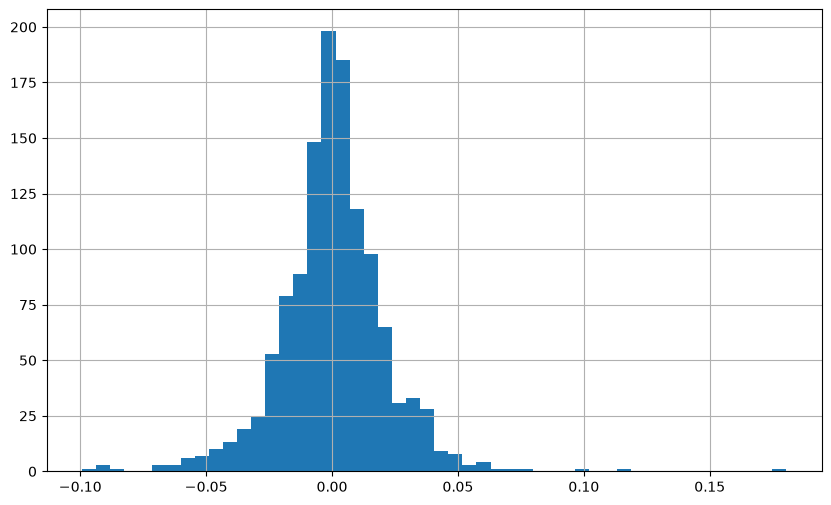

In [6]:
hist_SNK = SNK['Log_Return'].hist(bins=50, figsize=(10, 6))